# Inputs, lags e faltantes — Austrália em cinco minutos

Resolução real de **cinco minutos**, horizonte **t+5 minutos**. Os nomes dos arquivos foram mantidos por solicitação do usuário; o conteúdo foi migrado de diário para intradiário.

O alvo e a persistência (t−5 min) precisam ser originalmente medidos. Cada etapa de preenchimento causal usa até 15 minutos; no Brasil a combinação proxy + ffill pode atingir 30 minutos somente no histórico: nunca se interpola usando ponto posterior. Não se concatenam blocos interrompidos. A avaliação principal é diurna (elevação solar > 0); a avaliação 24h é complementar. Zero noturno não deve inflar a precisão.

As entradas principais são potência AC em p.u., hora local e dia do ano em seno/cosseno. O vento continua excluído. ERA5 nativa horária é auxiliar e não entra nos modelos principais. Estatísticas de normalização vêm apenas do treino australiano; alvos de validação/teste não ajustam escalas.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
RAIZ=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/energia_transfer').is_dir())
if str(RAIZ/'src') not in sys.path: sys.path.insert(0,str(RAIZ/'src'))
PASTA=RAIZ/'experimentos/transfer_learning_australia_brasil'
AU=RAIZ/'experimentos/australia_deep_learning'
REPORT=RAIZ/'reports/intradiario'
from energia_transfer.transfer_learning.dados import carregar,particao
_,CONFIG,CONTRATO=carregar(PASTA)
def exibir(t): display(t.round(5))


AUSTRALIA
BRASIL


,variavel,esperados,faltantes,faltantes_diurnos,maior_lacuna_min,faltantes_pct
0,Active_Power_original,1270529,59599,25023,20170,4.69088
1,Global_Horizontal_Radiation,1270529,46435,24424,30325,3.65478
2,Weather_Relative_Humidity,1270529,61011,29032,30325,4.80202
3,Weather_Temperature_Celsius,1270529,49518,26108,30325,3.89743


,timestamp,faltantes,faltantes_diurnos,validos,registro_ausente,maior_lacuna_global_min,esperados,faltantes_pct,variavel,dominio
0,2013-07-25,3,0,86,0,15,89,3.37079,Active_Power_original,australia
1,2013-07-26,3,0,285,0,15,288,1.04167,Active_Power_original,australia
2,2013-07-27,3,0,285,0,15,288,1.04167,Active_Power_original,australia
3,2013-07-28,3,0,285,0,15,288,1.04167,Active_Power_original,australia
4,2013-07-29,3,1,285,0,10,288,1.04167,Active_Power_original,australia
5,2013-07-30,4,2,284,0,10,288,1.38889,Active_Power_original,australia
6,2013-07-31,3,1,285,0,10,288,1.04167,Active_Power_original,australia
7,2013-08-01,3,0,285,0,15,288,1.04167,Active_Power_original,australia
8,2013-08-02,2,0,286,0,10,288,0.69444,Active_Power_original,australia
9,2013-08-03,3,1,285,0,15,288,1.04167,Active_Power_original,australia


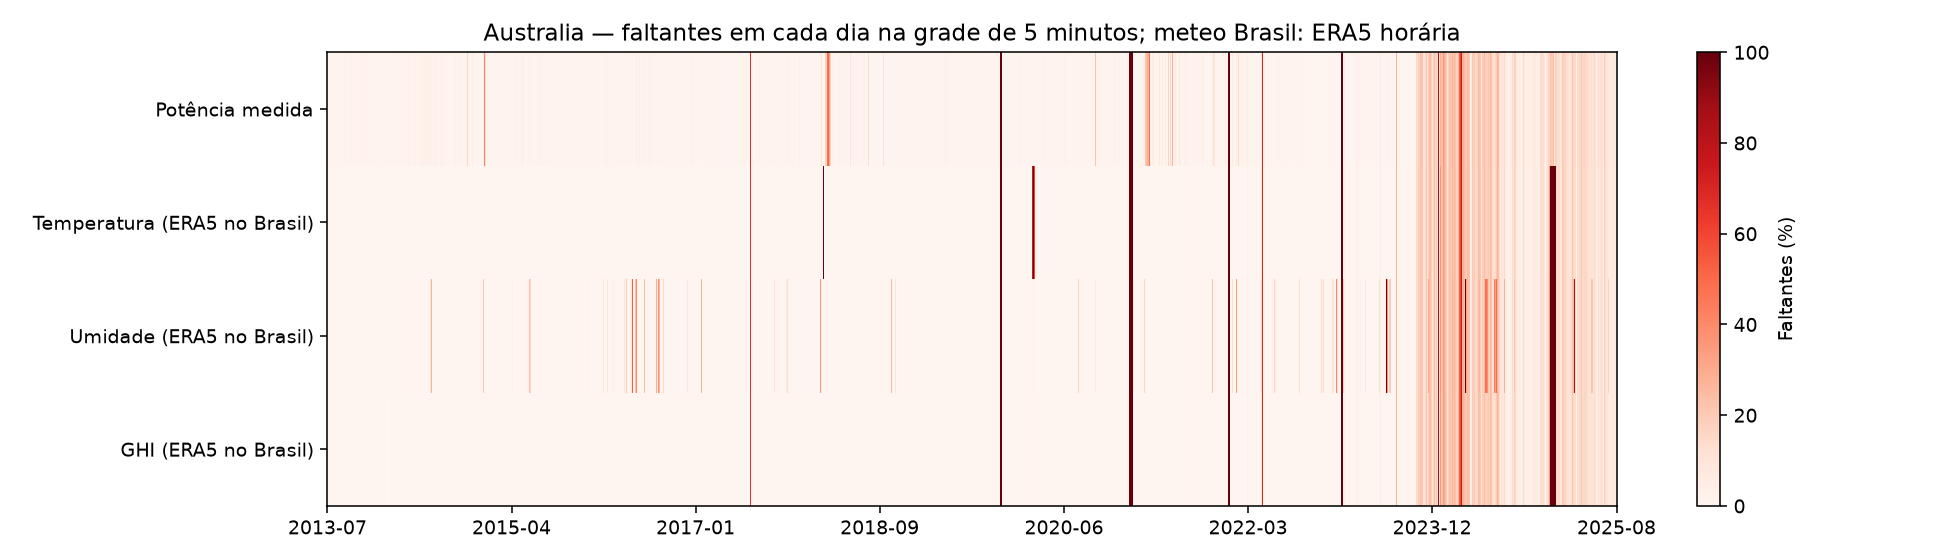

,campos_vazios,invalidos_operacionais
variavel,,
Active_Power,26826,18675
Global_Horizontal_Radiation,32326,11
Weather_Relative_Humidity,32365,14548
Weather_Temperature_Celsius,32374,3046


,variavel,esperados,faltantes,faltantes_diurnos,maior_lacuna_min,faltantes_pct
0,Active_Power_original,105120,15097,5407,3270,14.36168
1,Global_Horizontal_Radiation,105120,288,157,1440,0.27397
2,Weather_Relative_Humidity,105120,288,157,1440,0.27397
3,Weather_Temperature_Celsius,105120,288,157,1440,0.27397
4,ghi_estacao_original_escala_nao_validada,105120,71737,35316,301065,68.24296
5,temperatura_estacao_original,105120,71737,35316,301065,68.24296


,timestamp,faltantes,faltantes_diurnos,validos,registro_ausente,maior_lacuna_global_min,esperados,faltantes_pct,variavel,dominio
0,2025-01-01,22,6,266,16,60,288,7.63889,Active_Power_original,brasil
1,2025-01-02,21,6,267,13,55,288,7.29167,Active_Power_original,brasil
2,2025-01-03,39,25,249,31,75,288,13.54167,Active_Power_original,brasil
3,2025-01-04,21,8,267,12,55,288,7.29167,Active_Power_original,brasil
4,2025-01-05,25,11,263,18,55,288,8.68056,Active_Power_original,brasil
5,2025-01-06,26,14,262,19,55,288,9.02778,Active_Power_original,brasil
6,2025-01-07,24,9,264,22,55,288,8.33333,Active_Power_original,brasil
7,2025-01-08,25,7,263,19,55,288,8.68056,Active_Power_original,brasil
8,2025-01-09,21,7,267,14,55,288,7.29167,Active_Power_original,brasil
9,2025-01-10,23,7,265,14,55,288,7.98611,Active_Power_original,brasil


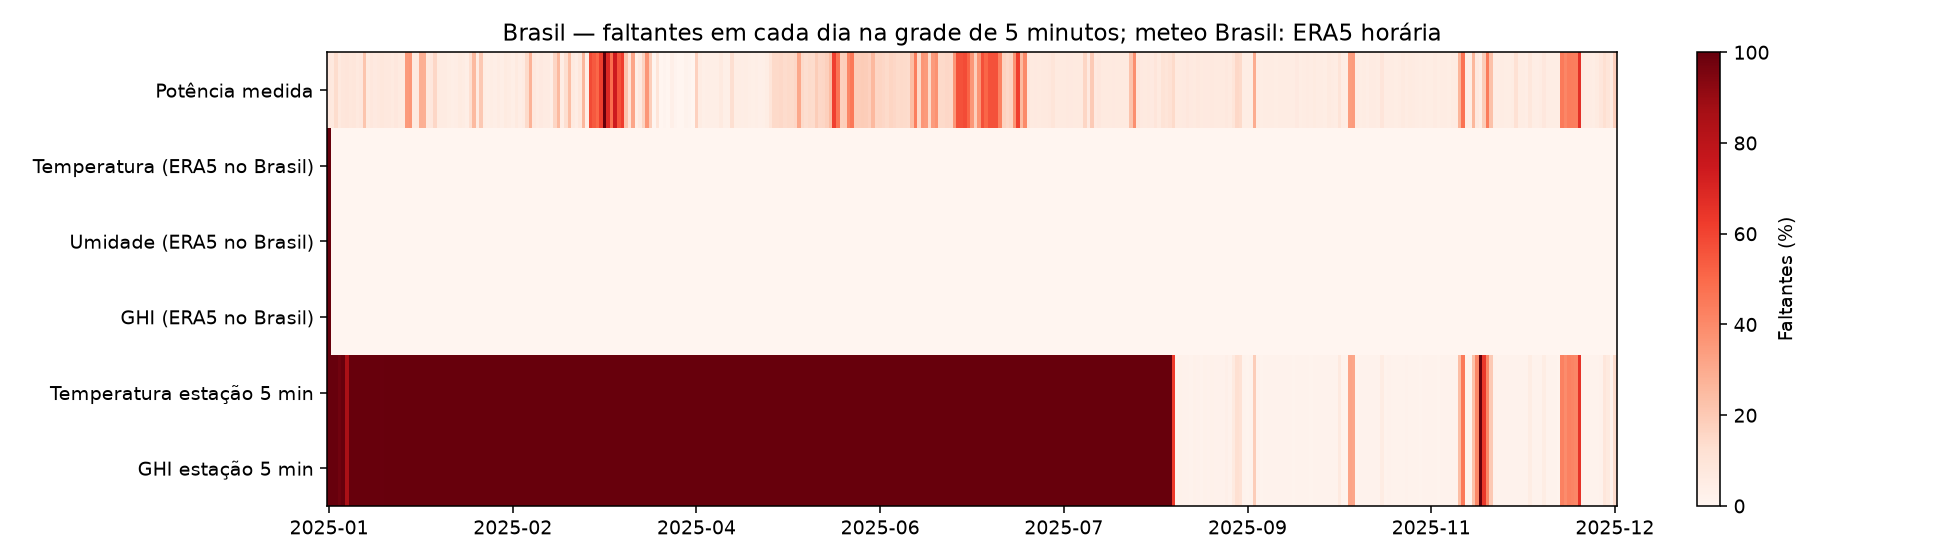

In [2]:
for dominio in ['australia','brasil']:
    print(dominio.upper())
    exibir(pd.read_csv(REPORT/f'faltantes_{dominio}_resumo.csv'))
    exibir(pd.read_csv(REPORT/f'faltantes_{dominio}_por_dia.csv').head(12))
    display(Image(filename=str(REPORT/f'faltantes_{dominio}_5min.png')))
    if dominio=='australia':
        exibir(pd.read_csv(REPORT/'invalidos_australia_por_dia.csv').groupby('variavel')[['campos_vazios','invalidos_operacionais']].sum())


In [3]:
exibir(pd.read_csv(PASTA/'resultados/particoes.csv'))
print('Inputs:',CONTRATO['variaveis_por_passo'])
print('Históricos:',[l*5 for l in CONFIG['lags']],'minutos; horizonte: 5 minutos')
print(CONTRATO['normalizacao'])


Inputs: ['Active_Power', 'hora_sin', 'hora_cos', 'dia_ano_sin', 'dia_ano_cos']
Históricos: [30, 60] minutos; horizonte: 5 minutos
Potência AC em p.u.; escalas do treino australiano diurno compartilhadas no Brasil.


,dominio,lag,historico_min,particao,janelas_antes_coorte,janelas,primeiro_alvo,ultimo_alvo
0,australia,6,30,treino,488964,40747,2013-07-25T17:05:00,2022-12-31T18:25:00
1,australia,12,60,treino,488448,40704,2013-07-25T17:35:00,2022-12-31T18:25:00
2,australia,6,30,validacao,46840,46840,2023-01-01T05:55:00,2023-12-31T19:20:00
3,australia,12,60,validacao,46840,46840,2023-01-01T05:55:00,2023-12-31T19:20:00
4,australia,6,30,teste,63393,63393,2024-01-01T06:00:00,2025-08-22T18:15:00
5,australia,12,60,teste,63393,63393,2024-01-01T06:00:00,2025-08-22T18:15:00
6,brasil,6,30,treino,32275,32275,2025-01-01T06:25:00,2025-09-30T18:10:00
7,brasil,12,60,treino,31874,31874,2025-01-01T06:55:00,2025-09-30T18:10:00
8,brasil,6,30,validacao,4043,4043,2025-10-01T06:00:00,2025-10-31T18:15:00
9,brasil,12,60,validacao,4043,4043,2025-10-01T06:00:00,2025-10-31T18:15:00


In [4]:
exibir(pd.read_csv(PASTA/'resultados/inputs_lags_validacao.csv'))

,historico_min,n_validacao,MAE_pu,RMSE_pu
0,30,46840,0.01703,0.03966
1,60,46840,0.01710,0.03966


## Reexecutar cálculos

Use o terminal para evitar treinos longos ocultos em uma célula:

```powershell
.venv\Scripts\python.exe experimentos\transfer_learning_australia_brasil\executar.py preparar
.venv\Scripts\python.exe experimentos\transfer_learning_australia_brasil\executar.py pretreinar
.venv\Scripts\python.exe experimentos\transfer_learning_australia_brasil\executar.py adaptar
.venv\Scripts\python.exe experimentos\transfer_learning_australia_brasil\executar.py avaliar
```

Históricos de 30 e 60 minutos (6/12 passos). São cinco sementes, MLP direta, MLP residual e LSTM direta. Treino fonte: uma de cada 12 janelas diurnas válidas, por custo de CPU, mantendo 2013–2022; validação 2023 e teste 2024–2025 em todos os instantes elegíveis. Treino brasileiro até setembro, validação outubro, teste novembro–dezembro de 2025. Os dados são autocorrelacionados: número de instantes não equivale a observações independentes. A configuração fixa máximos de 25 épocas fonte e 40 na adaptação; são experimentos iniciais, sem busca no teste.
